In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## Problem Statement

You have to Train an AI Model that can **predict `House Price`** based on house area/size.

## Dataset
Below is a dataset, having house area in square feat (sqft) and house price in \$1000s.

| Size (sqft) | Price (\$1000s) |
| ----------- | --------------- |
| 1           | 150             |
| 2           | 200             | 
| 3           | 250             | 
| 4           | 300             | 
| 5           | 350             | 


## Brain Storming
Before Training an AI Model, first think about the folllowing:
- is it a `Supervised` or Unsupervised learning problem?
- is it a Classification or `Regression` problem?
- What type of AI Models should I select for training?
- What are features/input `x`?
- What is the target/output variable `y`?
- How many samples `m` are there in the dataset?


In [1]:
# Simple Linear Regression with 1 variable (from scratch)

# Data
x = [1.0, 2.0, 3.0, 4.0, 5.0]  # House sizes (in 1000 sq ft)
y = [150, 200, 250, 300, 350]  # Prices (in $1000s)


In [2]:
# Hyperparameters
alpha = 0.01      # Learning rate
iterations = 1000

# Parameters initialization
w = 0.0  # weight (slope)
b = 0.0  # bias (intercept)

m = len(x)  # number of examples

In [3]:
# Gradient Descent
for it in range(iterations):
    sum_error_w = 0
    sum_error_b = 0

    for i in range(m):
        y_pred = w * x[i] + b
        error = y_pred - y[i]
        sum_error_w += error * x[i]
        sum_error_b += error

    # Update rule
    w -= alpha * (1 / m) * sum_error_w  
    b -= alpha * (1 / m) * sum_error_b

    # Print cost every 100 iterations
    if it % 100 == 0:
        cost = 0
        for i in range(m):
            y_pred = w * x[i] + b
            cost += (y_pred - y[i]) ** 2
        cost /= (2 * m)
        print(f"Iteration {it:4}: Cost = {cost:.4f}, w = {w:.4f}, b = {b:.4f}")

# Final output
print("\nFinal model: y = {:.2f}x + {:.2f}".format(w, b))

Iteration    0: Cost = 26364.2500, w = 8.5000, b = 2.5000
Iteration  100: Cost = 413.9701, w = 68.6807, b = 32.5560
Iteration  200: Cost = 295.1287, w = 65.7732, b = 43.0539
Iteration  300: Cost = 210.4039, w = 63.3180, b = 51.9177
Iteration  400: Cost = 150.0017, w = 61.2450, b = 59.4018
Iteration  500: Cost = 106.9396, w = 59.4947, b = 65.7210
Iteration  600: Cost = 76.2397, w = 58.0168, b = 71.0566
Iteration  700: Cost = 54.3530, w = 56.7690, b = 75.5617
Iteration  800: Cost = 38.7495, w = 55.7154, b = 79.3656
Iteration  900: Cost = 27.6254, w = 54.8258, b = 82.5774

Final model: y = 54.08x + 85.26


In [4]:
a = 55
b = 99.99
print("value of a is: ", a, "value of b is: ", b)
# print("value of b is: ", b)

print(f"value of a is: {a}, value of b is: {b} and datatype of b is: {type(b)}")

value of a is:  55 value of b is:  99.99
value of a is: 55, value of b is: 99.99 and datatype of b is: <class 'float'>


In [4]:
print(f"w: {w}, b: {b}")

w: 54.08153273498059, b: 85.26437176339627


In [5]:
# Data
x = [1.0, 2.0, 3.0, 4.0, 5.0]  # House sizes (in 1000 sq ft)
y = [150, 200, 250, 300, 350]  # Prices (in $1000s)

for i in range(len(x)):
    y_pred = w * x[i] + b
    print(f"Actual_value: {y[i]}   |     Predicted_value:{y_pred}")

Actual_value: 150   |     Predicted_value:139.34590449837685
Actual_value: 200   |     Predicted_value:193.42743723335747
Actual_value: 250   |     Predicted_value:247.50896996833805
Actual_value: 300   |     Predicted_value:301.59050270331863
Actual_value: 350   |     Predicted_value:355.6720354382992


Final model: y = 54.08x + 85.26


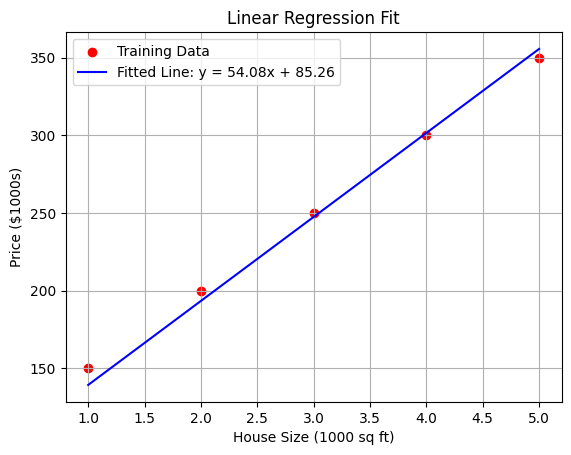


Predictions:
Size 1.5 => Predicted price: $166.39K
Size 3.5 => Predicted price: $274.55K
Size 6.0 => Predicted price: $409.75K


In [6]:
import matplotlib.pyplot as plt

# Original data
x = [1.0, 2.0, 3.0, 4.0, 5.0]
y = [150, 200, 250, 300, 350]

# Hyperparameters
alpha = 0.01
iterations = 1000

# Initialize parameters
w = 0.0
b = 0.0
m = len(x)

# Gradient Descent
for it in range(iterations):
    sum_error_w = 0
    sum_error_b = 0
    for i in range(m):
        y_pred = w * x[i] + b
        error = y_pred - y[i]
        sum_error_w += error * x[i]
        sum_error_b += error
    w -= alpha * (1 / m) * sum_error_w
    b -= alpha * (1 / m) * sum_error_b

# Final model
print("Final model: y = {:.2f}x + {:.2f}".format(w, b))

# --- Plotting ---
# Create predicted line
x_line = [min(x), max(x)]
y_line = [w * xi + b for xi in x_line]

plt.scatter(x, y, color='red', label='Training Data')
plt.plot(x_line, y_line, color='blue', label='Fitted Line: y = {:.2f}x + {:.2f}'.format(w, b))
plt.xlabel("House Size (1000 sq ft)")
plt.ylabel("Price ($1000s)")
plt.title("Linear Regression Fit")
plt.legend()
plt.grid(True)
plt.show()

# --- Prediction on New Data ---
def predict(x_val):
    return w * x_val + b

pred_values = []
test_inputs = [1.5, 3.5, 6.0]
print("\nPredictions:")
for xi in test_inputs:
    pred_values.append(predict(xi))
    print(f"Size {xi} => Predicted price: ${predict(xi):.2f}K")


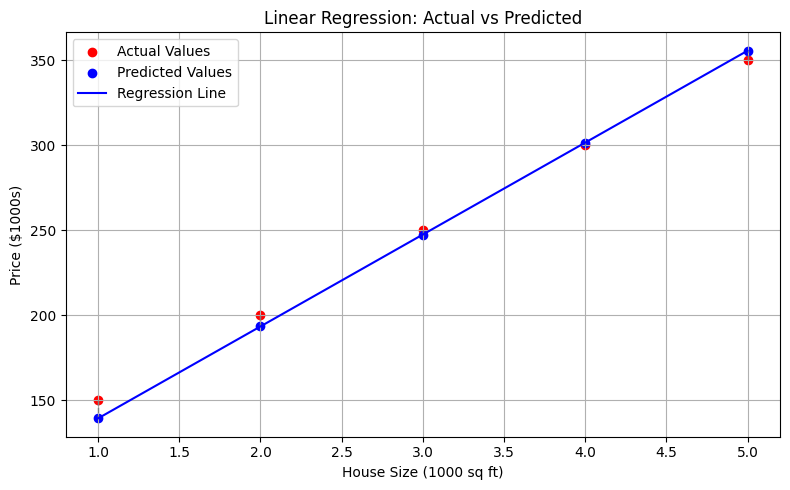


Predictions on new inputs:
Size 1.5 => Predicted price: $166.39K
Size 3.5 => Predicted price: $274.55K
Size 6.0 => Predicted price: $409.75K


In [7]:
# Predicted values for training data
y_predicted = [w * xi + b for xi in x]

# Line fit
x_line = [min(x), max(x)]
y_line = [w * xi + b for xi in x_line]

plt.figure(figsize=(8, 5))

# Plot actual values
plt.scatter(x, y, color='red', label='Actual Values')

# Plot predicted values
plt.scatter(x, y_predicted, color='blue', marker='o', label='Predicted Values')

# Optionally draw lines between actual and predicted for each point
for i in range(m):
    plt.plot([x[i], x[i]], [y[i], y_predicted[i]], color='gray', linestyle='--', linewidth=1)

# Plot fitted line
plt.plot(x_line, y_line, color='blue', linestyle='-', label='Regression Line')

# Labels and styling
plt.xlabel("House Size (1000 sq ft)")
plt.ylabel("Price ($1000s)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Prediction on New Test Inputs ---
def predict(x_val):
    return w * x_val + b

test_inputs = [1.5, 3.5, 6.0]
print("\nPredictions on new inputs:")
for xi in test_inputs:
    print(f"Size {xi} => Predicted price: ${predict(xi):.2f}K")

## Final Full Code without Plotting

In [8]:
# Training data
x = [1.0, 2.0, 3.0, 4.0, 5.0]
y = [150, 200, 250, 300, 350]

# Hyperparameters
alpha = 0.01
iterations = 1000

# Initialize parameters
w = 0.0
b = 0.0
m = len(x)

# Gradient Descent
for it in range(iterations):
    sum_error_w = 0
    sum_error_b = 0
    for i in range(m):
        y_pred = w * x[i] + b
        error = y_pred - y[i]
        sum_error_w += error * x[i]
        sum_error_b += error
    w -= alpha * (1 / m) * sum_error_w
    b -= alpha * (1 / m) * sum_error_b

# Final model
print("Final model: y = {:.2f}x + {:.2f}".format(w, b))

# Predictions for training data
for i in range(len(x)):
    y_pred = w * x[i] + b
    print(f"Actual_value: {y[i]}, Predicted_value:{y_pred:.2f}")

Final model: y = 54.08x + 85.26
Actual_value: 150, Predicted_value:139.35
Actual_value: 200, Predicted_value:193.43
Actual_value: 250, Predicted_value:247.51
Actual_value: 300, Predicted_value:301.59
Actual_value: 350, Predicted_value:355.67


## Final Full Code: Plot Actual, Predicted, and Test Inputs

Final model: y = 54.08x + 85.26


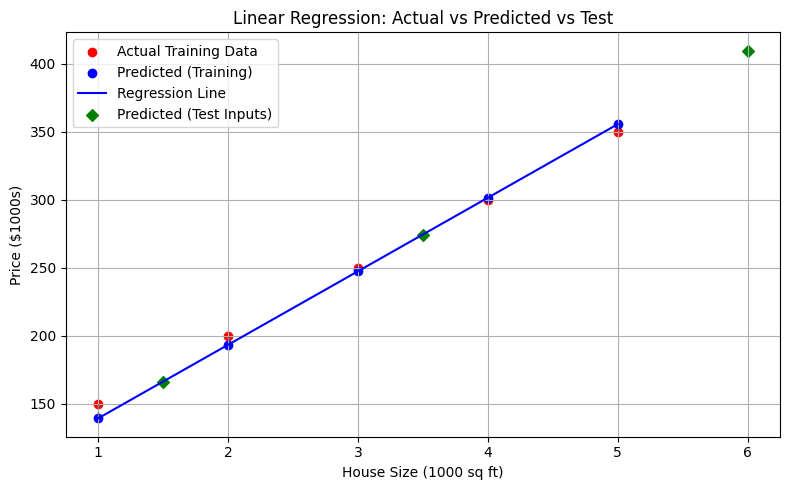


Predictions on new inputs:
Size 1.5 => Predicted price: $166.39K
Size 3.5 => Predicted price: $274.55K
Size 6.0 => Predicted price: $409.75K


In [9]:
import matplotlib.pyplot as plt

# Training data
x = [1.0, 2.0, 3.0, 4.0, 5.0]
y = [150, 200, 250, 300, 350]

# Hyperparameters
alpha = 0.01
iterations = 1000

# Initialize parameters
w = 0.0
b = 0.0
m = len(x)

# Gradient Descent
for it in range(iterations):
    sum_error_w = 0
    sum_error_b = 0
    for i in range(m):
        y_pred = w * x[i] + b
        error = y_pred - y[i]
        sum_error_w += error * x[i]
        sum_error_b += error
    w -= alpha * (1 / m) * sum_error_w
    b -= alpha * (1 / m) * sum_error_b

# Final model
print("Final model: y = {:.2f}x + {:.2f}".format(w, b))

# Predictions for training data
y_predicted = [w * xi + b for xi in x]

# --- Plotting ---
plt.figure(figsize=(8, 5))

# Actual training points
plt.scatter(x, y, color='red', label='Actual Training Data')

# Predicted training points
plt.scatter(x, y_predicted, color='blue', marker='o', label='Predicted (Training)')

# Draw error lines between actual and predicted
for i in range(m):
    plt.plot([x[i], x[i]], [y[i], y_predicted[i]], color='gray', linestyle='--', linewidth=1)

# Regression line
x_line = [min(x), max(x)]
y_line = [w * xi + b for xi in x_line]
plt.plot(x_line, y_line, color='blue', linestyle='-', label='Regression Line')

# --- Test inputs ---
test_inputs = [1.5, 3.5, 6.0]
test_predictions = [w * xi + b for xi in test_inputs]

# Plot test predictions
plt.scatter(test_inputs, test_predictions, color='green', marker='D', label='Predicted (Test Inputs)')

# Labels and styling
plt.xlabel("House Size (1000 sq ft)")
plt.ylabel("Price ($1000s)")
plt.title("Linear Regression: Actual vs Predicted vs Test")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Print test predictions ---
print("\nPredictions on new inputs:")
for xi, yp in zip(test_inputs, test_predictions):
    print(f"Size {xi:.1f} => Predicted price: ${yp:.2f}K")
